# 02.1 · What is a model? Features, target, prediction, error

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/02-regression/01-what-is-a-model/lesson.ipynb)

Read the [README](README.md) first. Here you build the vocabulary in code: features `X`, target `y`, predictions `y_hat`, errors, the baseline, and your first *trained* parameter, found with a loop instead of a formula.

## 1. The five customers: features and target

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd
five = pd.read_csv(data_path("shopwave_visits_spend_5.csv"))
five

,customer_id,visits_last_month,spend_next_month
0,C001,2,50
1,C002,4,80
2,C003,6,90
3,C004,8,130
4,C005,10,150


In [2]:
X = five[["visits_last_month"]]      # features: always a DataFrame (2-D), even with one column
y = five["spend_next_month"]         # target: a Series (1-D)
print("X shape:", X.shape, "  y shape:", y.shape)

X shape: (5, 1)   y shape: (5,)


## 2. Two models, no training

- **Model A (baseline)**: predict the mean of `y` for everyone.
- **Model B**: predict `10 × visits`.

The error for one row is `y - y_hat`. **MAE** is the mean of the absolute errors: pounds off, on average.

In [3]:
def mae(y, y_hat):
    return (y - y_hat).abs().mean()

y_hat_A = pd.Series(y.mean(), index=y.index)       # same number for every row
y_hat_B = 10 * five["visits_last_month"]

table = five.assign(A=y_hat_A, A_err=(y - y_hat_A).abs(), B=y_hat_B, B_err=(y - y_hat_B).abs())
display(table)
print(f"MAE  A (baseline) = £{mae(y, y_hat_A):.0f}      B (10 × visits) = £{mae(y, y_hat_B):.0f}")

,customer_id,visits_last_month,spend_next_month,A,A_err,B,B_err
0,C001,2,50,100.0,50.0,20,30
1,C002,4,80,100.0,20.0,40,40
2,C003,6,90,100.0,10.0,60,30
3,C004,8,130,100.0,30.0,80,50
4,C005,10,150,100.0,50.0,100,50


MAE  A (baseline) = £32      B (10 × visits) = £40


Model B looks at the feature and still loses to the baseline, because every guess is too low. Right shape, wrong knob.

## 3. Training by brute force

Model B has one parameter, the slope `k`. Try every `k` from 5 to 25 and keep the one with the lowest MAE. That *is* training; lesson 02.2 replaces the loop with a formula and 02.4 with a smarter search.

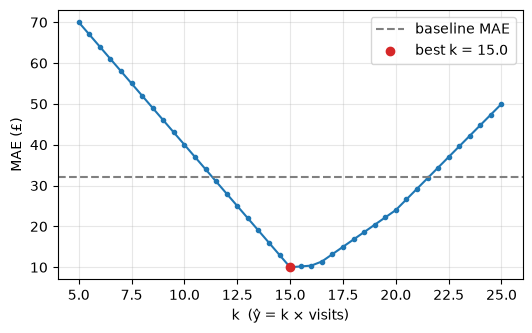

best k = 15.0, MAE = £10.0  (baseline £32)


In [4]:
import numpy as np
import matplotlib.pyplot as plt

ks = np.arange(5, 25.5, 0.5)
maes = [mae(y, k * five["visits_last_month"]) for k in ks]
best_k = ks[int(np.argmin(maes))]

plt.figure(figsize=(6, 3.5))
plt.plot(ks, maes, marker=".")
plt.axhline(mae(y, y_hat_A), color="gray", linestyle="--", label="baseline MAE")
plt.scatter([best_k], [min(maes)], color="tab:red", zorder=5, label=f"best k = {best_k}")
plt.xlabel("k  (ŷ = k × visits)"); plt.ylabel("MAE (£)"); plt.legend(); plt.grid(alpha=.3)
plt.show()
print(f"best k = {best_k}, MAE = £{min(maes):.1f}  (baseline £{mae(y, y_hat_A):.0f})")

The curve has a bottom. Its position is a **trained parameter**. Everything from here to neural networks is about finding the bottom of curves like this one, faster and in more dimensions.

## 4. The 20-customer table

In [5]:
cust20 = pd.read_csv(data_path("shopwave_customers_small.csv"))
cust20.head()

,customer_id,visits_last_month,items_last_month,days_since_last,country,spend_next_month,churned
0,C001,2,2,55,UK,27.61,1
1,C002,11,8,44,FR,220.42,0
2,C003,10,6,22,DE,176.21,0
3,C004,7,6,58,UK,127.58,1
4,C005,7,5,25,FR,150.95,1


In [6]:
X20 = cust20[["visits_last_month", "items_last_month", "days_since_last", "country"]]   # candidate features
y20 = cust20["spend_next_month"]                                                        # target

baseline20 = y20.mean()
print(f"baseline (mean) = £{baseline20:.2f}   MAE = £{mae(y20, pd.Series(baseline20, index=y20.index)):.2f}")

baseline (mean) = £159.57   MAE = £57.11


In [7]:
ks = np.arange(5, 30.5, 0.5)
for col in ["visits_last_month", "items_last_month"]:
    maes = [mae(y20, k * cust20[col]) for k in ks]
    print(f"ŷ = k × {col:<18}  best k = {ks[int(np.argmin(maes))]:>5}   MAE = £{min(maes):.2f}")

ŷ = k × visits_last_month   best k =  19.0   MAE = £11.36
ŷ = k × items_last_month    best k =  30.0   MAE = £20.27


Both one-knob models beat the £57 baseline comfortably. With a second knob (an intercept) they would do better still; 02.2 adds it.

## 5. The real data: what the baseline looks like at scale

The customer table from lesson 01.9: one row per customer, features from Dec 2010–Aug 2011, target = what they spent Sep–Nov 2011. (The leaky `recency_days` column is not built here.)

In [8]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, pandas as pd
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail

raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
print(raw.shape)
raw.head()


def clean_retail(df):
    """The standard ShopWave cleaning used from lesson 01.5 onwards."""
    out = df.copy()
    out = out[~out["Invoice"].astype(str).str.startswith("C")]   # drop cancellations
    out = out[(out["Quantity"] > 0) & (out["Price"] > 0)]         # drop returns / free items
    out = out.dropna(subset=["Customer ID"])                       # drop guest checkouts
    out = out.drop_duplicates()
    out["Customer ID"] = out["Customer ID"].astype(int)
    out["Revenue"] = out["Quantity"] * out["Price"]
    return out

sales = clean_retail(raw)
print(f"{len(raw):,} rows → {len(sales):,} after cleaning")


cutoff = pd.Timestamp("2011-09-01")
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(
    orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
    products=("StockCode", "nunique"), items=("Quantity", "sum"),
    first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"),
    country=("Country", "first"))
cust["avg_order"] = cust["spend"] / cust["orders"]
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
cust["spend_next_quarter"] = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust = cust.drop(columns=["first_order", "last_order"])
print(f"{len(cust):,} customers; features from before {cutoff.date()}, target = spend Sep–Nov 2011")
cust.head()

(541910, 8)
541,910 rows → 392,693 after cleaning
3,317 customers; features from before 2011-09-01, target = spend Sep–Nov 2011


,orders,spend,products,items,country,avg_order,tenure_days,days_since_last,spend_next_quarter
Customer ID,,,,,,,,,
12346,1,77183.60,1,74215,United Kingdom,77183.600000,225,225,0.00
12347,5,2790.86,82,1590,Iceland,558.172000,267,29,1294.32
12348,3,1487.24,22,2124,Finland,495.746667,258,148,310.00
12350,1,334.40,17,197,Norway,334.400000,210,210,0.00
12352,5,1561.81,26,254,Norway,312.362000,196,162,944.23


In [9]:
y_real = cust["spend_next_quarter"]
print(y_real.describe().round(1))

count      3317.0
mean        776.0
std        3926.9
min           0.0
25%           0.0
50%         170.6
75%         688.2
max      117634.5
Name: spend_next_quarter, dtype: float64


In [10]:
for name, guess in [("predict the mean", y_real.mean()), ("predict the median", y_real.median())]:
    print(f"{name:<20} ŷ = £{guess:8.1f}   MAE = £{mae(y_real, pd.Series(guess, index=y_real.index)):.1f}")

predict the mean     ŷ = £   776.0   MAE = £951.3
predict the median   ŷ = £   170.6   MAE = £761.5


Two baselines, off by £760–950 per customer. The mean is dragged up by a handful of wholesalers (max £117,634); the median is closer to a typical customer and has the lower MAE. Those two numbers are the bar for the rest of this module.

## Quiz answers

1. $y$ is the true value for a row; $\hat{y}$ is the model's prediction for it. Their difference is the error.
2. "Predict the mean" (or "predict the average of y").
3. Its parameter is wrong: the slope 10 makes every prediction too low. Training would set the slope (and add an intercept).
4. It is the target. It is not known on the day you make the prediction; using it would be leakage and the model would be useless on new customers.
5. $\theta$, the parameters. $f$ (the shape) and $\mathbf{x}$ (the data) stay fixed during training.

**Next:** [02.2 Linear regression by hand](../02-linear-regression-by-hand/)